# コード生成
gpt-4o-miniを用いて生成。

#### prompt
```prompt
# 依頼
ニューラルネットワーク回帰モデルのコード例を作成してください。
# 詳細
PyTorchを用いてください。
簡単なデータ例を作成してください。
隠れ層を１つとしたニューラルネットワークを作成してください。
```

#### answer
作成結果は以下です。

Epoch [100/1000], Loss: 0.1427
Epoch [200/1000], Loss: 0.0871
Epoch [300/1000], Loss: 0.0420
Epoch [400/1000], Loss: 0.0231
Epoch [500/1000], Loss: 0.0174
Epoch [600/1000], Loss: 0.0157
Epoch [700/1000], Loss: 0.0155
Epoch [800/1000], Loss: 0.0154
Epoch [900/1000], Loss: 0.0153
Epoch [1000/1000], Loss: 0.0153


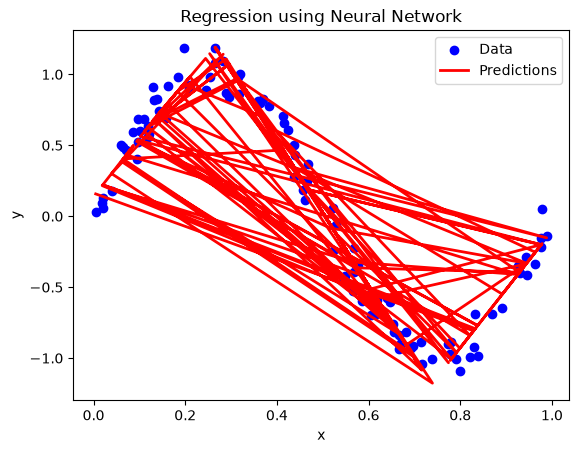

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# データの生成
# 1次元のデータを生成します (x: 0から1のランダム値, y: sin(2 * pi * x) + ノイズ)
np.random.seed(0)  # 再現性のために乱数シードを固定
x = np.random.rand(100, 1)  # 100個のサンプルを生成
y = np.sin(2 * np.pi * x) + 0.1 * np.random.randn(100, 1)  # ノイズを加えた出力

# numpy配列をPyTorchのテンソルに変換
X_train = torch.FloatTensor(x)
y_train = torch.FloatTensor(y)

# ニューラルネットワークモデルの定義
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.hidden = nn.Linear(1, 10)  # 隠れ層 (入力次元: 1, 出力次元: 10)
        self.relu = nn.ReLU()            # 活性化関数
        self.output = nn.Linear(10, 1)   # 出力層 (入力次元: 10, 出力次元: 1)

    def forward(self, x):
        x = self.hidden(x)
        x = self.relu(x)
        x = self.output(x)
        return x

# モデル、損失関数、最適化手法の初期化
model = SimpleNN()
criterion = nn.MSELoss()  # 平均二乗誤差損失関数
optimizer = optim.Adam(model.parameters(), lr=0.01)  # Adamオプティマイザ

# 学習ループ
num_epochs = 1000
for epoch in range(num_epochs):
    model.train()  # モデルを訓練モードにセット
    optimizer.zero_grad()  # 勾配を初期化

    # フォワードパス
    predictions = model(X_train)

    # 損失計算
    loss = criterion(predictions, y_train)

    # バックプロパゲーション
    loss.backward()
    optimizer.step()

    # 進捗の表示
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}')

# モデルの評価
model.eval()  # モデルを評価モードにセット
with torch.no_grad():
    y_pred = model(X_train).numpy()

# 結果のプロット
plt.scatter(x, y, color='blue', label='Data')
plt.plot(x, y_pred, color='red', label='Predictions', linewidth=2)
plt.title('Regression using Neural Network')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


上のコードは図示部分がおかしいので以下で修正した。

エポック数を多くすると妥当な回帰モデルが学習できる。ただし、訓練データ・テストデータ分割はなし。


修正後

Epoch [100/1000], Loss: 0.1746
Epoch [200/1000], Loss: 0.1399
Epoch [300/1000], Loss: 0.0851
Epoch [400/1000], Loss: 0.0571
Epoch [500/1000], Loss: 0.0328
Epoch [600/1000], Loss: 0.0196
Epoch [700/1000], Loss: 0.0163
Epoch [800/1000], Loss: 0.0156


Epoch [900/1000], Loss: 0.0155
Epoch [1000/1000], Loss: 0.0155


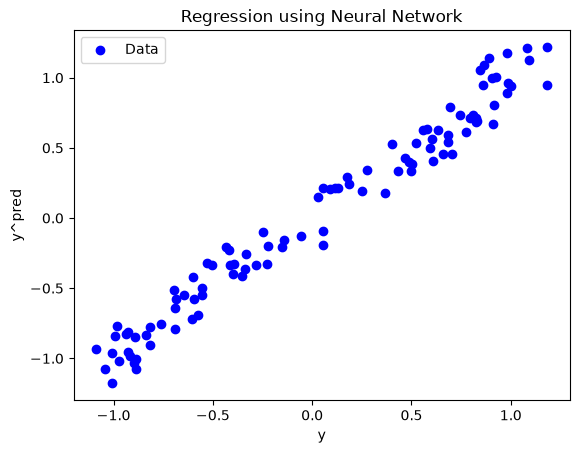

In [2]:

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# データの生成
# 1次元のデータを生成します (x: 0から1のランダム値, y: sin(2 * pi * x) + ノイズ)
np.random.seed(0)  # 再現性のために乱数シードを固定
x = np.random.rand(100, 1)  # 100個のサンプルを生成
y = np.sin(2 * np.pi * x) + 0.1 * np.random.randn(100, 1)  # ノイズを加えた出力

# numpy配列をPyTorchのテンソルに変換
X_train = torch.FloatTensor(x)
y_train = torch.FloatTensor(y)

# ニューラルネットワークモデルの定義
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.hidden = nn.Linear(1, 10)  # 隠れ層 (入力次元: 1, 出力次元: 10)
        self.relu = nn.ReLU()            # 活性化関数
        self.output = nn.Linear(10, 1)   # 出力層 (入力次元: 10, 出力次元: 1)

    def forward(self, x):
        x = self.hidden(x)
        x = self.relu(x)
        x = self.output(x)
        return x

# モデル、損失関数、最適化手法の初期化
model = SimpleNN()
criterion = nn.MSELoss()  # 平均二乗誤差損失関数
optimizer = optim.Adam(model.parameters(), lr=0.01)  # Adamオプティマイザ

# 学習ループ
num_epochs = 1000
for epoch in range(num_epochs):
    model.train()  # モデルを訓練モードにセット
    optimizer.zero_grad()  # 勾配を初期化

    # フォワードパス
    predictions = model(X_train)

    # 損失計算
    loss = criterion(predictions, y_train)

    # バックプロパゲーション
    loss.backward()
    optimizer.step()

    # 進捗の表示
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}')

# モデルの評価
model.eval()  # モデルを評価モードにセット
with torch.no_grad():
    y_pred = model(X_train).numpy()

# 結果のプロット
plt.scatter(y,y_pred, color='blue', label='Data')
plt.title('Regression using Neural Network')
plt.xlabel('y')
plt.ylabel('y^pred')
plt.legend()
plt.show()

### prompt
```
コードをブロック毎に説明してください。
```


![](fig/8200-NN-simple-explain1.png)


![](fig/8200-NN-simple-explain3-4.png)


![](fig/8200-NN-simple-explain5.png)


![](fig/8200-NN-simple-explain6.png)


![](fig/8200-NN-simple-explain7.png)


## まとめると以下の枠組みになっています。

![](fig/8200-NN-simple-code-summary.jpg)


## 数式での説明

以下の部分を言葉でなく数式で説明してほしい。

```code
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.hidden = nn.Linear(1, 10)  # 隠れ層 (入力次元: 1, 出力次元: 10)
        self.relu = nn.ReLU()            # 活性化関数
        self.output = nn.Linear(10, 1)   # 出力層 (入力次元: 10, 出力次元: 1)

    def forward(self, x):
        x = self.hidden(x)
        x = self.relu(x)
        x = self.output(x)
        return x
```

### prompt
```prompt
SimpleNNクラスを数式で説明してください。

```

### answser

SimpleNNクラス

**隠れ層**

$$
h = W_1 x + b_1
$$

**活性化関数**

$$
h' = \mathrm{ReLU}(h) = \max(0,, h)
$$

**出力層**

$$
y = W_2 h' + b_2
$$

ここで、

* $W$: 重み行列
* $b$: バイアス


![](fig/8200-NN-ReLU.jpg)


## Backpropagation部分
ニューラルネットワークモデルの一般的な説明として
「逆伝播（Backpropagation）」がありました。


### prompt
```prompt
backpropagationはコードのどこで計算されますか。
```

### answer
![](fig/8200-NN-simple-backpropagation1.png)


## オプティマイザ部分

モデルの𝑊や𝑏の値を最適化し、損失関数を最小化します。
こを行う最適化手法には何があるでしょうか？

### prompt
```prompt
Adam以外に使用できるオプティマイザを教えてください。
```

![](fig/8200-NN-simple-optimizer.png)

全部紹介されているわけではありません。（PyTorchの新版がでるタイミングでは昔の版の紹介をすることもあります。）
これらが最新版の紹介かはhttps://pytorch.org/docs/stable/optim.htmlを御覧ください。
学習率についても説明を求めてみてください。




## ドロップアウトとバッチ正則化

コードの説明で「ドロップアウトやバッチ正則化」が出てきた。

実は作成されたコードではドロップアウトもバッチ正則化も有効になっていませんが、もし定義され有効であったら、という説明でした。

まず、ドロップアウトやバッチ正則化を尋ねます。

### prompt
```prompt
ドロップアウトやバッチ正則化を説明してください。
```

### answer
ドロップアウトはニューラルネットワークモデルの過学習を防ぐための手法。
訓練中にランダムにいくつかのニューロンを無効とする。具体的に無効とはニューロンの出力を０とする。

なお、評価モードでは全部のニューロンが使用されます。

文献：
 Nitish Srivastava, Geoffrey Hinton, Alex Krizhevsky, Ilya Sutskever, Ruslan Salakhutdinov;  Dropout: A Simple Way to Prevent Neural Networks from Overfitting, JMLR 15(56):1929−1958, 2014. 

![](fig/8200-NN-simple-batchnormalization.png)

文献：Sergey Ioffe, Christian Szegedy, Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift, ICML'15: Proceedings of the 32nd International Conference on International Conference on Machine Learning - 37,  448 - 456




### prompt
```prompt
ドロップアウトとバッチ正則化を有効にしたコードを作成してください。
```

### answer
![](fig/8200-NN-simple-batchnorm-dropout-code.jpg)

問題なく作成できる。
ただ、パラメタが妥当かどうかは別の話。


以下がドロップアウト、バッチ正則化を有効にしたコード

Epoch [100/3000], Loss: 0.1424
Epoch [200/3000], Loss: 0.0971


Epoch [300/3000], Loss: 0.0956
Epoch [400/3000], Loss: 0.1189
Epoch [500/3000], Loss: 0.1614


Epoch [600/3000], Loss: 0.1274
Epoch [700/3000], Loss: 0.1121


Epoch [800/3000], Loss: 0.1178
Epoch [900/3000], Loss: 0.1102
Epoch [1000/3000], Loss: 0.0988


Epoch [1100/3000], Loss: 0.1356
Epoch [1200/3000], Loss: 0.1333


Epoch [1300/3000], Loss: 0.1404
Epoch [1400/3000], Loss: 0.1108
Epoch [1500/3000], Loss: 0.1129


... (2 outputs left out)

Epoch [2100/3000], Loss: 0.1435
Epoch [2200/3000], Loss: 0.1492


Epoch [2300/3000], Loss: 0.1146
Epoch [2400/3000], Loss: 0.1320
Epoch [2500/3000], Loss: 0.1250


Epoch [2600/3000], Loss: 0.0959
Epoch [2700/3000], Loss: 0.1281


Epoch [2800/3000], Loss: 0.1272
Epoch [2900/3000], Loss: 0.1147
Epoch [3000/3000], Loss: 0.1000


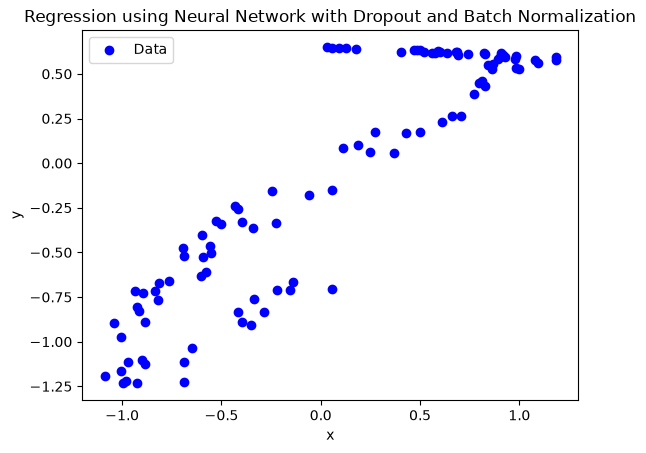

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# データの生成
np.random.seed(0)  # 再現性のために乱数シードを固定
x = np.random.rand(100, 1)  # 100個のサンプルを生成
y = np.sin(2 * np.pi * x) + 0.1 * np.random.randn(100, 1)  # ノイズを加えた出力

# numpy配列をPyTorchのテンソルに変換
X_train = torch.FloatTensor(x)
y_train = torch.FloatTensor(y)

# ニューラルネットワークモデルの定義
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.hidden = nn.Linear(1, 10)  # 隠れ層
        self.batch_norm = nn.BatchNorm1d(10)  # バッチ正則化
        self.relu = nn.ReLU()            # 活性化関数
        self.dropout = nn.Dropout(0.2)   # ドロップアウト (50%の確率でニューロンを無効化)
        self.output = nn.Linear(10, 1)   # 出力層

    def forward(self, x):
        x = self.hidden(x)               # 隠れ層へのパス
        x = self.batch_norm(x)           # バッチ正則化
        x = self.relu(x)                 # 活性化関数の適用
        x = self.dropout(x)               # ドロップアウトの適用
        x = self.output(x)               # 出力層へのパス
        return x

# モデル、損失関数、最適化手法の初期化
model = SimpleNN()
criterion = nn.MSELoss()              # 平均二乗誤差損失関数
optimizer = optim.Adam(model.parameters(), lr=0.01)  # Adamオプティマイザ

# 学習ループ
num_epochs = 3000
for epoch in range(num_epochs):
    model.train()  # モデルを訓練モードにセット
    optimizer.zero_grad()  # 勾配を初期化

    # フォワードパス
    predictions = model(X_train)

    # 損失計算
    loss = criterion(predictions, y_train)

    # バックプロパゲーション
    loss.backward()
    optimizer.step()

    # 進捗の表示
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}')

# モデルの評価
model.eval()  # モデルを評価モードにセット
with torch.no_grad():
    y_pred = model(X_train).numpy()

# 結果のプロット
plt.scatter(y, y_pred, color='blue', label='Data')
plt.title('Regression using Neural Network with Dropout and Batch Normalization')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

### prompt
```prompt
# 依頼
コードを修正してください。
# 詳細
ドロップアウトとバッチ正則化を無効します。
全データを訓練データとテストデータに分けます。
epoch毎に損失関数の値を図示してください。
テストデータで回帰モデルの評価指標MAE，R２，RMSEを出力してください。
y vs y_predの図を書いてください。
```

### コードの変更点

1. ドロップアウトとバッチ正則化の無効化:
   - モデル定義でドロップアウトとバッチ正則化は行わず、隠れ層と出力層だけを使用しています。

2. データの分割:
   - `train_test_split` を用いてデータを80%の訓練用と20%のテスト用に分割しています。

3. 損失値の図示:
   - エポック毎に記録した損失値をプロットしています。

4. 評価指標の計算:
   - `mean_absolute_error`, `r2_score`, `mean_squared_error` をそれぞれ用いて、テストデータに対するモデルの評価を行い、結果を表示しています。

5. y vs y_predのプロット:
   - テストデータの真の値と予測値を比較して散布図を生成し、理想的な予測（y=xの線）を描画しています。


以下が、生成されたコードです。

Epoch [100/1000], Loss: 0.1890
Epoch [200/1000], Loss: 0.1736
Epoch [300/1000], Loss: 0.1634
Epoch [400/1000], Loss: 0.1491
Epoch [500/1000], Loss: 0.1002
Epoch [600/1000], Loss: 0.0420
Epoch [700/1000], Loss: 0.0210
Epoch [800/1000], Loss: 0.0164


Epoch [900/1000], Loss: 0.0151
Epoch [1000/1000], Loss: 0.0148


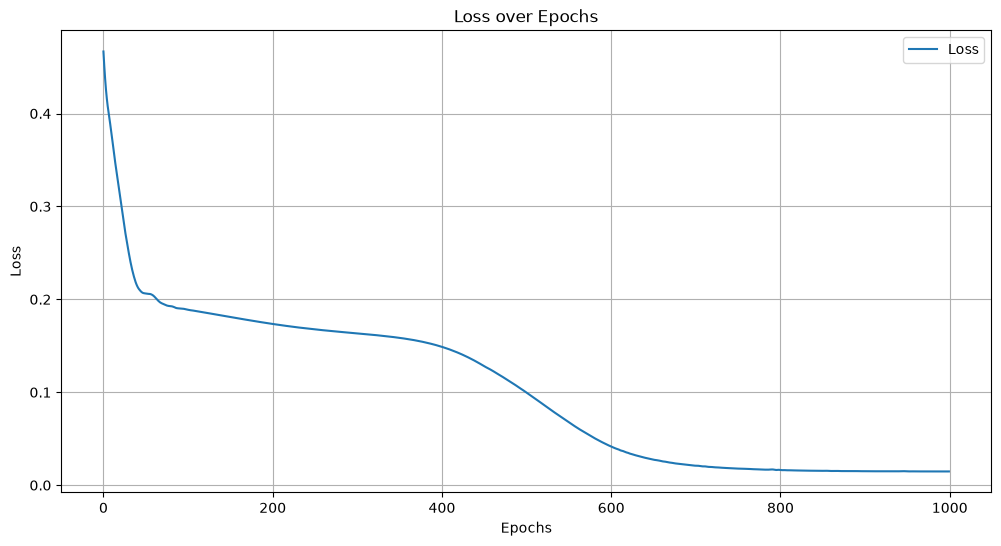

Mean Absolute Error (MAE): 0.1205
R² Score: 0.9539
Root Mean Squared Error (RMSE): 0.0198


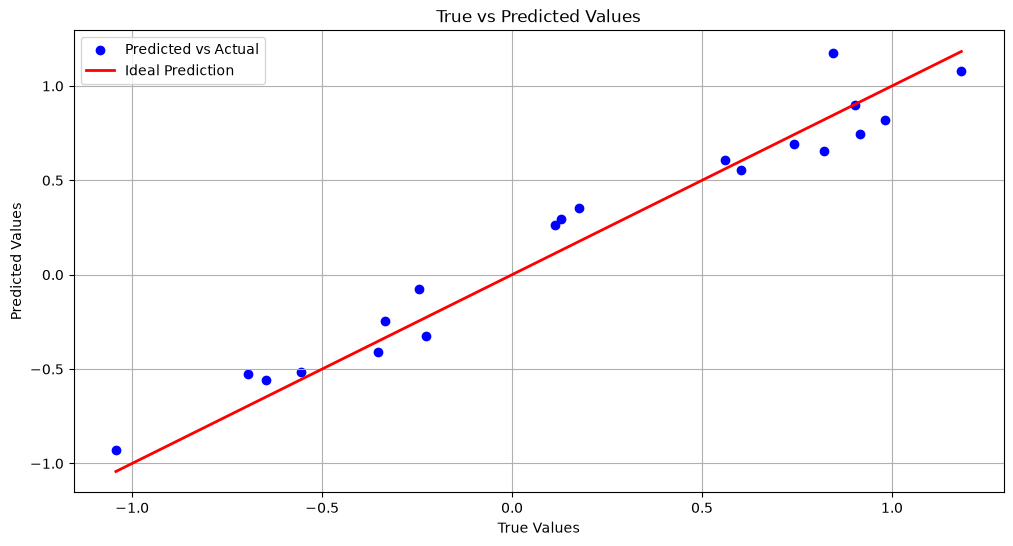

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

# データの生成
np.random.seed(0)  # 再現性のために乱数シードを固定
x = np.random.rand(100, 1)  # 100個のサンプルを生成
y = np.sin(2 * np.pi * x) + 0.1 * np.random.randn(100, 1)  # ノイズを加えた出力

# numpy配列をPyTorchのテンソルに変換
X = torch.FloatTensor(x)
y = torch.FloatTensor(y)

# データの分割 (80%を訓練データ、20%をテストデータ)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# ニューラルネットワークモデルの定義
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.hidden = nn.Linear(1, 10)  # 隠れ層
        self.relu = nn.ReLU()            # 活性化関数
        self.output = nn.Linear(10, 1)   # 出力層

    def forward(self, x):
        x = self.hidden(x)               # 隠れ層へのパス
        x = self.relu(x)                 # 活性化関数の適用
        x = self.output(x)               # 出力層へのパス
        return x

# モデル、損失関数、最適化手法の初期化
model = SimpleNN()
criterion = nn.MSELoss()              # 平均二乗誤差損失関数
optimizer = optim.Adam(model.parameters(), lr=0.01)  # Adamオプティマイザ

# 学習ループ
num_epochs = 1000
losses = []  # 損失を保持するリスト

for epoch in range(num_epochs):
    model.train()  # モデルを訓練モードにセット
    optimizer.zero_grad()  # 勾配を初期化

    # フォワードパス
    predictions = model(X_train)

    # 損失計算
    loss = criterion(predictions, y_train)
    losses.append(loss.item())  # 損失をリストに追加

    # バックプロパゲーション
    loss.backward()
    optimizer.step()

    # 進捗の表示
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}')

# モデルの評価
model.eval()  # モデルを評価モードにセット
with torch.no_grad():
    y_pred = model(X_test).numpy()  # テストデータに対する予測

# エポックごとに損失の値を図示
plt.figure(figsize=(12, 6))
plt.plot(range(num_epochs), losses, label='Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# 評価指標の計算
mae = mean_absolute_error(y_test.numpy(), y_pred)
r2 = r2_score(y_test.numpy(), y_pred)
# rmse = mean_squared_error(y_test.numpy(), y_pred, squared=False) # squared=Falseがあると原因不明なエラーが起きる。
rmse = mean_squared_error(y_test.numpy(), y_pred)

print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'R² Score: {r2:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')

# y vs y_predの図を作成
plt.figure(figsize=(12, 6))
plt.scatter(y_test.numpy(), y_pred, color='blue', label='Predicted vs Actual')
plt.plot([min(y_test.numpy()), max(y_test.numpy())], 
         [min(y_test.numpy()), max(y_test.numpy())], 
         color='red', label='Ideal Prediction', linewidth=2)
plt.title('True vs Predicted Values')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()
plt.grid()
plt.show()

## 回帰コードの修正：説明変数の要素数の変更

説明変数が一つのコードだったので、
説明変数を５つに増やします。


### prompt

```
# 依頼
コードを修正してください。
# 詳細
説明変数が５つのデータを用いてください。
ドロップアウトを有効にします。
全データを訓練データとテストデータに分けます。
epoch毎に損失関数の値を図示してください。
テストデータで回帰モデルの評価指標MAE，R２，RMSEを出力してください。
y vs y_predの図を書いてください。
```

例えば、SimpleNNクラスは以下のように変わります。
![](fig/8200-NN-simple-5variables.jpg)


Epoch [100/1000], Loss: 0.2619
Epoch [200/1000], Loss: 0.3010
Epoch [300/1000], Loss: 0.2929


Epoch [400/1000], Loss: 0.2752
Epoch [500/1000], Loss: 0.2995
Epoch [600/1000], Loss: 0.2589
Epoch [700/1000], Loss: 0.3016


Epoch [800/1000], Loss: 0.2609
Epoch [900/1000], Loss: 0.2875
Epoch [1000/1000], Loss: 0.2652


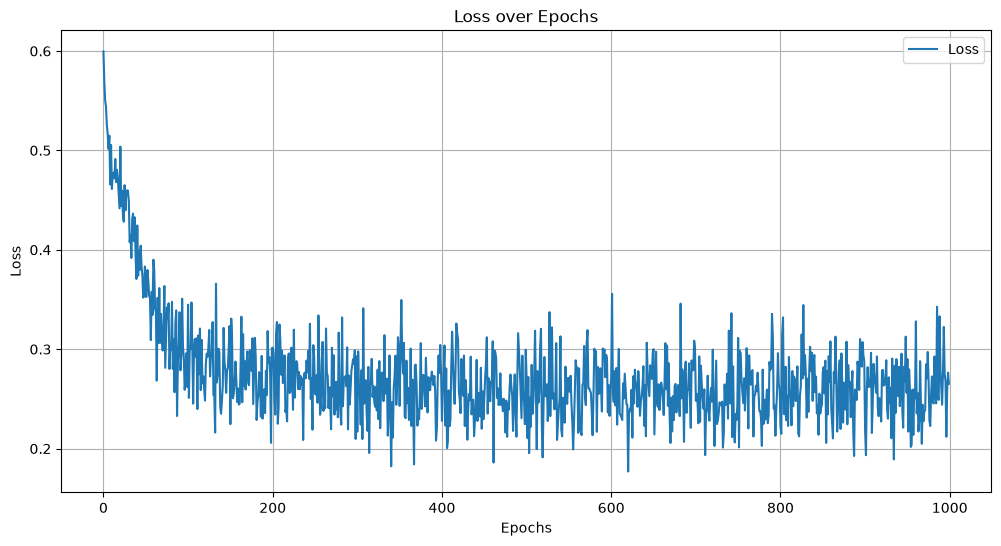

Mean Absolute Error (MAE): 0.4014
R² Score: 0.6464
Root Mean Squared Error (RMSE): 0.2142


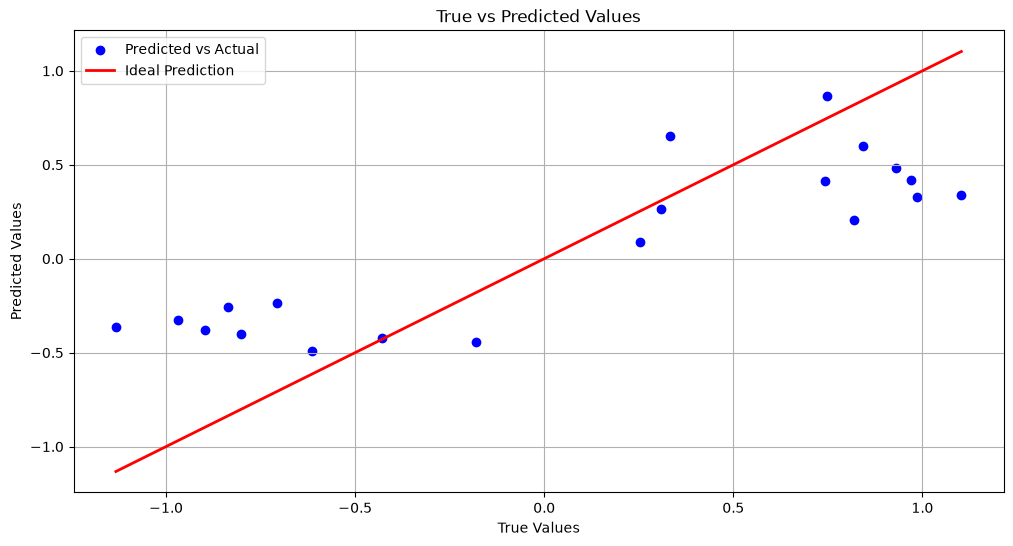

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

# データの生成
np.random.seed(0)  # 再現性のために乱数シードを固定
X = np.random.rand(100, 5)  # 100個のサンプル、5つの特徴量
y = np.sin(2 * np.pi * X[:, 0]) + 0.1 * np.random.randn(100)  # ノイズを加えた出力 (1つの特徴量による)

# numpy配列をPyTorchのテンソルに変換
X_tensor = torch.FloatTensor(X)
y_tensor = torch.FloatTensor(y).view(-1, 1)

# データの分割 (80%を訓練データ、20%をテストデータ)
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=0)

# ニューラルネットワークモデルの定義
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.hidden = nn.Linear(5, 10)  # 隠れ層 (5つの特徴量を入力)
        self.relu = nn.ReLU()            # 活性化関数
        self.dropout = nn.Dropout(0.5)   # ドロップアウト (50%の確率でニューロンを無効化)
        self.output = nn.Linear(10, 1)   # 出力層

    def forward(self, x):
        x = self.hidden(x)               # 隠れ層へのパス
        x = self.relu(x)                 # 活性化関数の適用
        x = self.dropout(x)              # ドロップアウトの適用
        x = self.output(x)               # 出力層へのパス
        return x

# モデル、損失関数、最適化手法の初期化
model = SimpleNN()
criterion = nn.MSELoss()              # 平均二乗誤差損失関数
optimizer = optim.Adam(model.parameters(), lr=0.01)  # Adamオプティマイザ

# 学習ループ
num_epochs = 1000
losses = []  # 損失を保持するリスト

for epoch in range(num_epochs):
    model.train()  # モデルを訓練モードにセット
    optimizer.zero_grad()  # 勾配を初期化

    # フォワードパス
    predictions = model(X_train)

    # 損失計算
    loss = criterion(predictions, y_train)
    losses.append(loss.item())  # 損失をリストに追加

    # バックプロパゲーション
    loss.backward()
    optimizer.step()

    # 進捗の表示
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}')

# モデルの評価
model.eval()  # モデルを評価モードにセット
with torch.no_grad():
    y_pred = model(X_test).numpy()  # テストデータに対する予測

# エポックごとに損失の値を図示
plt.figure(figsize=(12, 6))
plt.plot(range(num_epochs), losses, label='Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# 評価指標の計算
mae = mean_absolute_error(y_test.numpy(), y_pred)
r2 = r2_score(y_test.numpy(), y_pred)
# rmse = mean_squared_error(y_test.numpy(), y_pred, squared=False)
rmse = mean_squared_error(y_test.numpy(), y_pred)

print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'R² Score: {r2:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')

# y vs y_predの図を作成
plt.figure(figsize=(12, 6))
plt.scatter(y_test.numpy(), y_pred, color='blue', label='Predicted vs Actual')
plt.plot([min(y_test.numpy()), max(y_test.numpy())], 
         [min(y_test.numpy()), max(y_test.numpy())], 
         color='red', label='Ideal Prediction', linewidth=2)
plt.title('True vs Predicted Values')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()
plt.grid()
plt.show()

# 回帰コードの修正：GPUの利用

「簡単に」CPUとGPUを使い変えることが出来るのがPyTorchの利点の一つです。

![](fig/8200-NN-cpu-gpu.jpg)

### prompt
```prompt
GPUを使うように書き直してください。
```

この時はGPUがあれば、GPUを用いるコードを生成しました。

![](fig/8200-NN-GPU-device.jpg)


Epoch [100/1000], Loss: 0.2541
Epoch [200/1000], Loss: 0.2264


Epoch [300/1000], Loss: 0.2382
Epoch [400/1000], Loss: 0.2964
Epoch [500/1000], Loss: 0.2514
Epoch [600/1000], Loss: 0.2711
Epoch [700/1000], Loss: 0.2576


Epoch [800/1000], Loss: 0.2864
Epoch [900/1000], Loss: 0.2874


Epoch [1000/1000], Loss: 0.1911


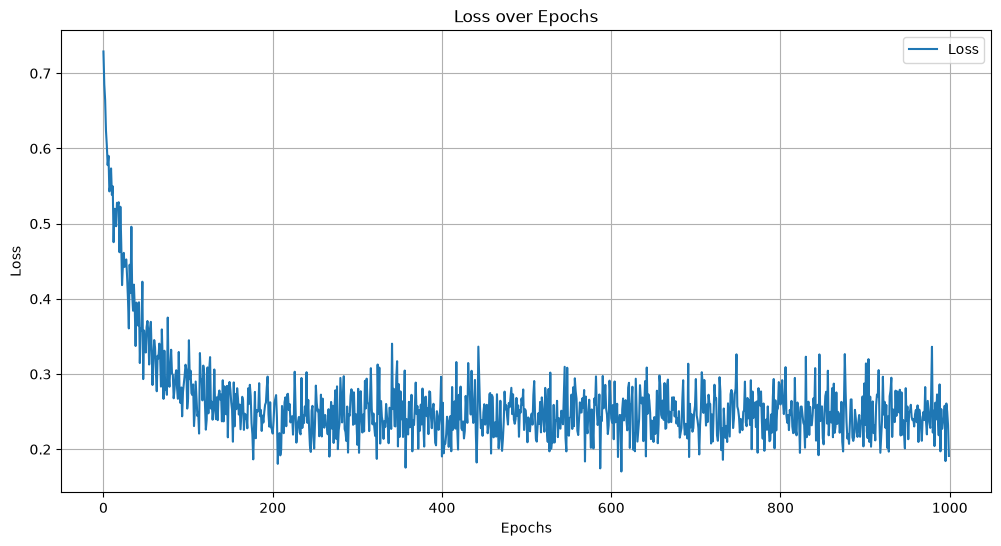

Mean Absolute Error (MAE): 0.3595
R² Score: 0.7069
Root Mean Squared Error (RMSE): 0.1775


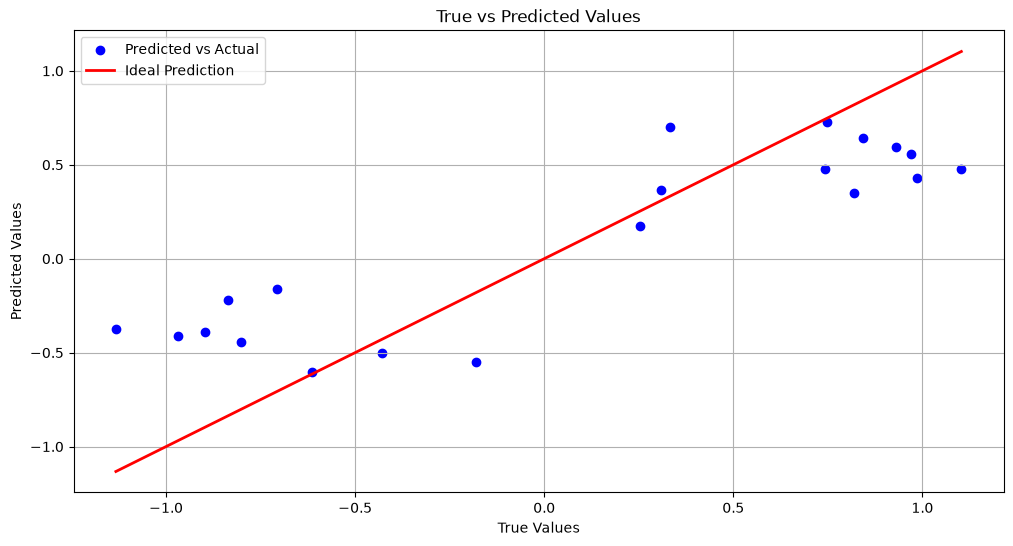

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

# データの生成
np.random.seed(0)  # 再現性のために乱数シードを固定
X = np.random.rand(100, 5)  # 100個のサンプル、5つの特徴量
y = np.sin(2 * np.pi * X[:, 0]) + 0.1 * np.random.randn(100)  # ノイズを加えた出力

# numpy配列をPyTorchのテンソルに変換
X_tensor = torch.FloatTensor(X)
y_tensor = torch.FloatTensor(y).view(-1, 1)

# データの分割 (80%を訓練データ、20%をテストデータ)
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=0)

# GPUの使用を確認
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# データをGPUに転送
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# ニューラルネットワークモデルの定義
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.hidden = nn.Linear(5, 10)  # 隠れ層 (5つの特徴量を入力)
        self.relu = nn.ReLU()            # 活性化関数
        self.dropout = nn.Dropout(0.5)   # ドロップアウト (50%の確率でニューロンを無効化)
        self.output = nn.Linear(10, 1)   # 出力層

    def forward(self, x):
        x = self.hidden(x)               # 隠れ層へのパス
        x = self.relu(x)                 # 活性化関数の適用
        x = self.dropout(x)              # ドロップアウトの適用
        x = self.output(x)               # 出力層へのパス
        return x

# モデルをGPUに転送
model = SimpleNN().to(device)

# 損失関数と最適化手法の初期化
criterion = nn.MSELoss()              # 平均二乗誤差損失関数
optimizer = optim.Adam(model.parameters(), lr=0.01)  # Adamオプティマイザ

# 学習ループ
num_epochs = 1000
losses = []  # 損失を保持するリスト

for epoch in range(num_epochs):
    model.train()  # モデルを訓練モードにセット
    optimizer.zero_grad()  # 勾配を初期化

    # フォワードパス
    predictions = model(X_train)

    # 損失計算
    loss = criterion(predictions, y_train)
    losses.append(loss.item())  # 損失をリストに追加

    # バックプロパゲーション
    loss.backward()
    optimizer.step()

    # 進捗の表示
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}')

# モデルの評価
model.eval()  # モデルを評価モードにセット
with torch.no_grad():
    y_pred = model(X_test).cpu().numpy()  # テストデータに対する予測をCPUへ転送してNumPyに変換

# エポックごとに損失の値を図示
plt.figure(figsize=(12, 6))
plt.plot(range(num_epochs), losses, label='Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# 評価指標の計算
mae = mean_absolute_error(y_test.cpu().numpy(), y_pred)
r2 = r2_score(y_test.cpu().numpy(), y_pred)
# rmse = mean_squared_error(y_test.cpu().numpy(), y_pred, squared=False)
rmse = mean_squared_error(y_test.cpu().numpy(), y_pred)

print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'R² Score: {r2:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')

# y vs y_predの図を作成
plt.figure(figsize=(12, 6))
plt.scatter(y_test.cpu().numpy(), y_pred, color='blue', label='Predicted vs Actual')
plt.plot([min(y_test.cpu().numpy()), max(y_test.cpu().numpy())], 
         [min(y_test.cpu().numpy()), max(y_test.cpu().numpy())], 
         color='red', label='Ideal Prediction', linewidth=2)
plt.title('True vs Predicted Values')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()
plt.grid()
plt.show()

# 回帰コードの修正：ReCoデータへの適用


100.regression/で用いたReCoデータを用いる。

- 入力層のサイズをPとする。
- 隠れ層を２層にする。

### prompt
```prompt
# 依頼
class SimpleNN(nn.Module):
のニューラルネットワークモデルを書き換えてください。
# 詳細
隠れ層を２層にします。
入力層のサイズをPとします
```

X,yを読み込む部分は自分で修正する。


![](fig/8200-NN-simple-ReCo.jpg)


In [7]:
import get_data
DATA_NAME = "ReCo"
df_obs,descriptor_names, target_name = get_data.load(DATA_NAME, "..")
Xraw = df_obs.loc[:, descriptor_names].values
y = df_obs.loc[:, target_name].values
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = scaler.fit_transform(Xraw)
P = X.shape[1]
print(P)

11


Epoch [100/1000], Loss: 150626.0625
Epoch [200/1000], Loss: 15776.5830


Epoch [300/1000], Loss: 10874.4287
Epoch [400/1000], Loss: 8696.5020
Epoch [500/1000], Loss: 6942.5962


Epoch [600/1000], Loss: 4964.1626


Epoch [700/1000], Loss: 4073.1436
Epoch [800/1000], Loss: 3611.7336


Epoch [900/1000], Loss: 3197.5662
Epoch [1000/1000], Loss: 2887.5173


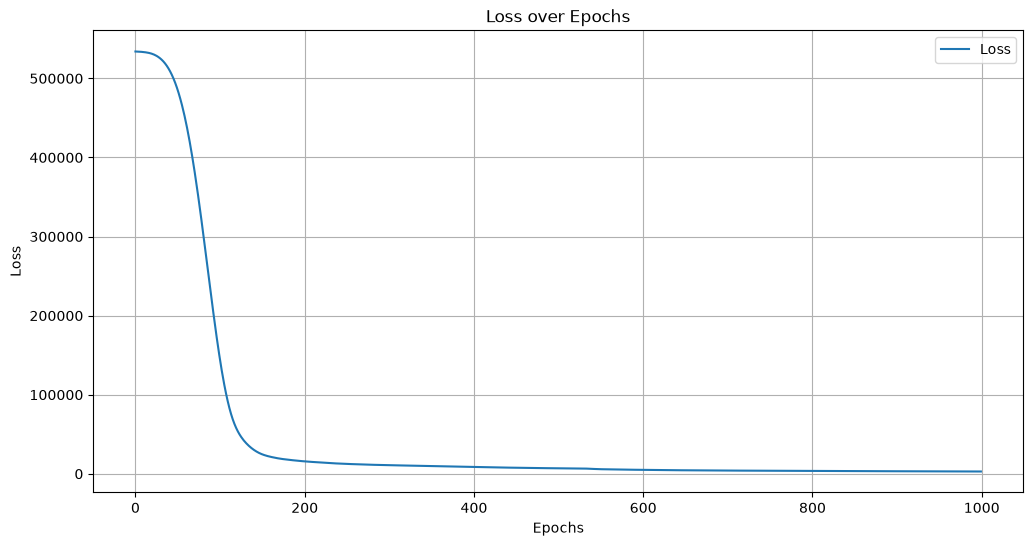

Mean Absolute Error (MAE): 55.2177
R² Score: 0.9693
Root Mean Squared Error (RMSE): 4580.5786


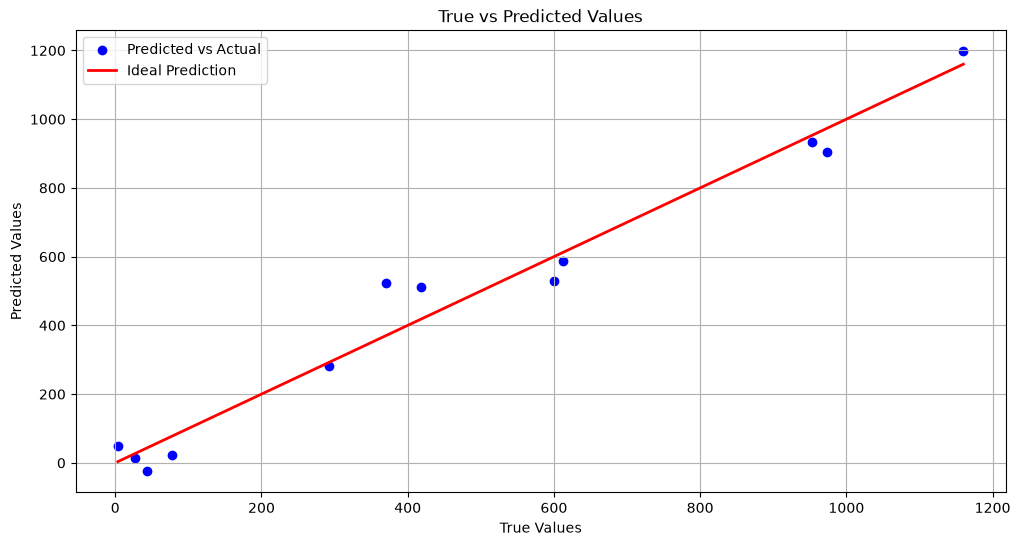

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

# データの生成
# np.random.seed(0)  # 再現性のために乱数シードを固定
# X = np.random.rand(100, 5)  # 100個のサンプル、5つの特徴量
# y = np.sin(2 * np.pi * X[:, 0]) + 0.1 * np.random.randn(100)  # ノイズを加えた出力

# numpy配列をPyTorchのテンソルに変換
X_tensor = torch.FloatTensor(X)
y_tensor = torch.FloatTensor(y).view(-1, 1)

# データの分割 (80%を訓練データ、20%をテストデータ)
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=0)

# GPUの使用を確認
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# データをGPUに転送
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# ---------書き換え部分
# ニューラルネットワークモデルの定義
class SimpleNN(nn.Module):
    def __init__(self, P):
        super(SimpleNN, self).__init__()
        self.hidden1 = nn.Linear(P, 10)  # 隠れ層1
        self.hidden2 = nn.Linear(10, 5)  # 隠れ層2
        self.output = nn.Linear(5, 1)  # 出力層
    
    def forward(self, x):
        x = torch.relu(self.hidden1(x))
        x = torch.relu(self.hidden2(x))
        return self.output(x)

# モデルをGPUに転送
model = SimpleNN(P).to(device)
# ---------書き換え部分ここまで

# 損失関数と最適化手法の初期化
criterion = nn.MSELoss()              # 平均二乗誤差損失関数
optimizer = optim.Adam(model.parameters(), lr=0.01)  # Adamオプティマイザ

# 学習ループ
num_epochs = 1000
losses = []  # 損失を保持するリスト

for epoch in range(num_epochs):
    model.train()  # モデルを訓練モードにセット
    optimizer.zero_grad()  # 勾配を初期化

    # フォワードパス
    predictions = model(X_train)

    # 損失計算
    loss = criterion(predictions, y_train)
    losses.append(loss.item())  # 損失をリストに追加

    # バックプロパゲーション
    loss.backward()
    optimizer.step()

    # 進捗の表示
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}')

# モデルの評価
model.eval()  # モデルを評価モードにセット
with torch.no_grad():
    y_pred = model(X_test).cpu().numpy()  # テストデータに対する予測をCPUへ転送してNumPyに変換

# エポックごとに損失の値を図示
plt.figure(figsize=(12, 6))
plt.plot(range(num_epochs), losses, label='Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# 評価指標の計算
mae = mean_absolute_error(y_test.cpu().numpy(), y_pred)
r2 = r2_score(y_test.cpu().numpy(), y_pred)
# rmse = mean_squared_error(y_test.cpu().numpy(), y_pred, squared=False)
rmse = mean_squared_error(y_test.cpu().numpy(), y_pred)

print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'R² Score: {r2:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')

# y vs y_predの図を作成
plt.figure(figsize=(12, 6))
plt.scatter(y_test.cpu().numpy(), y_pred, color='blue', label='Predicted vs Actual')
plt.plot([min(y_test.cpu().numpy()), max(y_test.cpu().numpy())], 
         [min(y_test.cpu().numpy()), max(y_test.cpu().numpy())], 
         color='red', label='Ideal Prediction', linewidth=2)
plt.title('True vs Predicted Values')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()
plt.grid()
plt.show()